In [1]:
import sys
import os

# Define the absolute path to the directory containing your module
module_folder_path = r'C:\Users\manue\OneDrive - University of Illinois - Urbana\Research\River corridor\inverse-river-transport\code' 


# Append the path to sys.path
sys.path.append(os.path.abspath(module_folder_path)) 
import utils
import forward
import estimators


import inspect

import numpy as np
import matplotlib.pyplot as plt

import scipy as sp
from scipy.stats import chi2

import csv

from matplotlib.colors import LogNorm

In [2]:
for module in [forward,estimators,utils]:
    print(module.__name__)
    for i, name_obj in enumerate(inspect.getmembers(module)):
        if '__' not in name_obj[0]:
            print('   ├--->',name_obj[0])
            for n,o in inspect.getmembers(name_obj[1],inspect.isfunction):
                if i != len(inspect.getmembers(module))-1:
                    print('   |       ├--->',n)
                else:
                    print('           ├--->',n)

forward
   ├---> laplace
           ├---> ADEMF_1D
           ├---> invlap
estimators
   ├---> PBI
   |       ├---> KL_coeffs
   |       ├---> drop_points_in_simplex
   |       ├---> estimate_params_NNI
   |       ├---> estimate_params_PBI
   |       ├---> get_projected_points
   |       ├---> get_projected_points_basis
   |       ├---> get_projecting_basis
   |       ├---> get_vertices_basis
   |       ├---> gs
   |       ├---> proj
   |       ├---> test_err_rand_KL_coeffs
   ├---> laplace
   |       ├---> ADEMF_1D
   ├---> moments
           ├---> ADEFO_1D
           ├---> TSM_moms_analyt
           ├---> TSM_moms_meas
utils
   ├---> dimensional_reduction
   |       ├---> KL_decomposition
   ├---> errors
   |       ├---> KL_div_func
   |       ├---> RMSD_func
   |       ├---> RMSE_func
   |       ├---> compute_errors
   ├---> invlap
   |       ├---> invlap
   ├---> load_btcs
   |       ├---> data
   ├---> synthetic
           ├---> ADEMF_1D
           ├---> generate
           ├---> 

In [3]:
help(estimators.laplace.ADEMF_1D)

Help on function ADEMF_1D in module estimators.laplace:

ADEMF_1D(t, btc, x, memory_func, bound_cond, params0, ns=10000)
    Estimates parameters of measured breakthrough curves by fitting in Laplace domain.
    - t (array): Times of measurement of concentrations
    - btc (array): Measured concentrations (same length as t)
    - memory_func (str): Either 'first order' or 'power law', others can be added editing beta_g_est_lap
    - bound_cond (str): Either 'semi-infinite-conc', 'semi-infinite-mixed', or 'infinite'
                'semi-infinite-conc' is a domain x>0 with vc(x=0,t)=M_0 delta(t)
                'semi-infinite-mixed' is a domain x>0 with vc(x=0,t)- 2 D dc/dx (x=0,t) =M_0 delta(t)
                'infinite' is a domain x>0 with vc(x=0,t)-2 D dc/dx (x=0,t) =M_0 delta(t). The solution to this problem is equivalent to the solution in the infinite domain
    - params0 (array of length 4): Initial guess of parameters. Default is v_ref and geometric mean of bounds. If bounds ar

In [4]:
with open(r"C:\Users\manue\OneDrive - University of Illinois - Urbana\Research\River corridor\inverse-river-transport\data\river_solute_tracer_data.csv", 'r') as file:
    data_reader = csv.reader(file)
    data_mat = [[cell for cell in row] for row in data_reader]
    breakthrough_curves_data = [[[data_mat[i][i_btc*5+j] for i in range(len(data_mat))] for j in range(4)] for i_btc in range(len(data_mat[0])//5)]

In [5]:
indices_valid = [i for i,btc in enumerate(breakthrough_curves_data) if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
ts_m = [np.array([float(c) for c in breakthrough_curves_data[i][0][33:] if c!='']) for i in indices_valid]
btcs_m = [np.array([float(c) for c in breakthrough_curves_data[i][3][33:] if c!='']) for i in indices_valid]
n_btcs = len(btcs_m)
for i_btc in range(n_btcs):
    if len(ts_m[i_btc])<len(btcs_m[i_btc]):
        btcs_m[i_btc] = btcs_m[i_btc][:len(ts_m[i_btc])]
indices_unphysical = []
for i_btc in range(n_btcs):
    t,btc = ts_m[i_btc],btcs_m[i_btc]
    frac_ext = 1/3
    t_frac,btc_frac = t[btc>0][-int(len(btc[btc>0])*frac_ext):],np.log(btc[btc>0][-int(len(btc[btc>0])*frac_ext):])
    a,b = np.polyfit(t_frac,btc_frac,1)
    moms = estimators.moments.TSM_moms_meas(t,btc)
    if moms[2]<0 or a>0:
        indices_unphysical.append(indices_valid[i_btc])
for i in indices_unphysical:
    indices_valid.remove(i)
np.random.seed(42)
# indices_valid = list(np.random.choice(indices_valid,40,replace = False))

In [6]:
ts_m = [np.array([float(c) for c in breakthrough_curves_data[i][0][33:] if c!='']) for i in indices_valid]
btcs_m = [np.array([float(c) for c in breakthrough_curves_data[i][3][33:] if c!='']) for i in indices_valid]
xs_m = [breakthrough_curves_data[i][2][18] for i in indices_valid]
xs_m = [float(i) if i!='' else 0.0 for i in xs_m]
background_cs_m = [breakthrough_curves_data[i][2][25]  for i in indices_valid]
background_cs_m = [float(i) if i!='' else 0.0 for i in background_cs_m]
names_list = [breakthrough_curves_data[i][0][31]  for i in indices_valid]
n_btcs = len(ts_m)
rivers_list = [n.split(' ')[0] for n in names_list]
rivers_full_name_list = [breakthrough_curves_data[i][2][1] for i in indices_valid]
tracers_list = [' '.join(n.split(' ')[:2])+' '+''.join([j  if ('S'+j in n.split(' ')[-1]) else '' for j in list('ABCDEFGHIJKLMNOPQRSTUVWXYZ')]) for n in names_list]
unique_tracers_list = list(set(tracers_list))
_,count_tracers = np.unique([unique_tracers_list.index(i) for i in tracers_list], return_counts = True)
np.random.seed(1)
random_shuffle = np.arange(len(count_tracers))
np.random.shuffle(random_shuffle)

In [7]:
for i_btc in range(n_btcs):
    if len(ts_m[i_btc])<len(btcs_m[i_btc]):
        btcs_m[i_btc] = btcs_m[i_btc][:len(ts_m[i_btc])]
T_= int(max([t[-1]/t[np.argmax(btc)] for t,btc in zip(ts_m,btcs_m)]))+1
print(T_)

24


In [8]:
ts_m_0 = []
btcs_m_0 = []
for i_btc in range(n_btcs):
    t,btc = ts_m[i_btc],btcs_m[i_btc]
    sorted_indices = np.argsort(t)
    t = t[sorted_indices]
    btc = btc[sorted_indices]
    t_unique,indices_unique = np.unique(t, return_index=True)
    if len(t_unique)!=len(t):
        btc_unique = np.zeros(len(indices_unique))
        for i in range(len(indices_unique)):
            if i<len(indices_unique)-1:
                btc_unique[i] = np.mean(btc[indices_unique[i]:indices_unique[i+1]])
            else:
                btc_unique[i] = np.mean(btc[indices_unique[i]:])
        t = t_unique
        btc = btc_unique
        ts_m[i_btc],btcs_m[i_btc] = t,btc
    deltat = np.median(t[1:]-t[:-1])
    t_ext = np.concatenate((np.arange(t[0],0,-deltat)[1:][::-1],t,np.arange(t[-1],max(t[-1],T_*t[np.argmax(btc)]),deltat)[1:]))
    btc_ext = np.interp(t_ext,t,btc-background_cs_m[i_btc],left = 0.0,right = 0.0)
    btc_ext = btc_ext
    ts_m_0.append(t_ext)
    btcs_m_0.append(btc_ext)

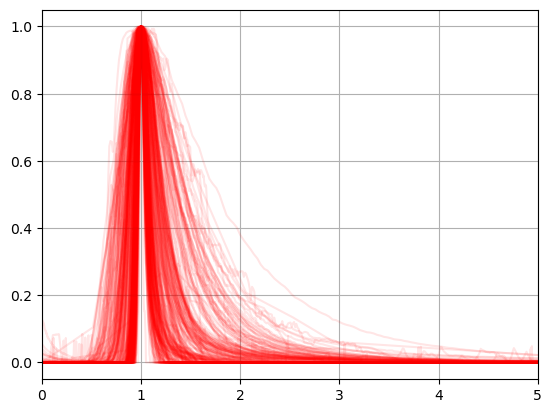

In [9]:
for i_btc in range(n_btcs):
    ts,btc = ts_m_0[i_btc],btcs_m_0[i_btc]
    plt.grid()
    plt.plot(ts/ts[np.argmax(btc)],btc/np.max(btc), c = 'r', alpha = 0.1)
    plt.xlim(0,5)

## Parameter estimation

In [10]:
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

In [11]:
memory_func = 'first order'
bound_cond = 'infinite'

In [12]:
vs_peak = np.array([x/ts_meas[np.argmax(measured_bt)] for ts_meas,measured_bt,x in zip(ts_m_0,btcs_m_0,xs_m)])
ts_peak = np.array([ts_meas[np.argmax(measured_bt)] for ts_meas,measured_bt,x in zip(ts_m_0,btcs_m_0,xs_m)])

In [13]:
%%time
def estimate_laplace(i_btc):
    t,btc,x, v_ref = ts_m_0[i_btc],btcs_m_0[i_btc],xs_m[i_btc], vs_peak[i_btc]
    t_pos = t[btc>0]
    btc_pos = btc[btc>0]
    if memory_func == 'first order':
        params0 = np.array([vs_peak[i_btc],100.0,3.0,30.0])
    if memory_func == 'power law':
        params0 = np.array([vs_peak[i_btc],100.0,0.3,0.5])
    params = estimators.laplace.ADEMF_1D(t_pos,btc_pos,x,memory_func,bound_cond,params0)
    if memory_func == 'first order':
        if t[0]==0:
            btc_rec = np.concatenate(([0.0],forward.laplace.ADEMF_1D(t[1:],[x],params[0],min(params[1],20000),params[2]/params[3],[params[3],params[3]],memory_func,bound_cond)[:,-1]))
        else:
            btc_rec = forward.laplace.ADEMF_1D(t,[x],params[0],min(params[1],20000),params[2]/params[3],[params[3],params[3]],memory_func,bound_cond)[:,-1]
    if memory_func == 'power law':
        if t[0]==0:
            btc_rec = np.concatenate(([0.0],forward.laplace.ADEMF_1D(t[1:],[x],params[0],min(params[1],20000),1.0,[params[2],params[3]],memory_func,bound_cond)[:,-1]))
        else:
            btc_rec = forward.laplace.ADEMF_1D(t,[x],params[0],min(params[1],20000),1.0,[params[2],params[3]],memory_func,bound_cond)[:,-1]
    RMSD = utils.errors.RMSD_func(t,btc,btc_rec)
    KL_div = utils.errors.KL_div_func(t,btc,btc_rec)
    if memory_func == 'power law':
        params[-1] = np.exp(params[-1])
    return params,RMSD,KL_div,btc_rec
output_estimate_laplace = [estimate_laplace(i_btc) for i_btc in range(n_btcs)]
params_laplace = np.array([out[0] for out in output_estimate_laplace])
RMSDs_laplace = np.array([out[1] for out in output_estimate_laplace])
KL_divs_laplace = np.array([out[2] for out in output_estimate_laplace])
btcs_rec_laplace = [out[3] for out in output_estimate_laplace]

CPU times: total: 46.2 s
Wall time: 47.2 s


In [14]:
%%time
if memory_func == 'first order':
    def estimate_moments(i_btc):
        t,btc,x = ts_m_0[i_btc],btcs_m_0[i_btc],xs_m[i_btc]
        v_prior = x/t[np.argmax(btc)]
        params0 =  np.array([v_prior,300.0,3.0,30.0])
        params = estimators.moments.ADEFO_1D(t,btc,x,bound_cond,params0)
        if t[0]==0:
            btc_rec = np.concatenate(([0.0],forward.laplace.ADEMF_1D(t[1:],[x],params[0],min(params[1],20000),params[2]/params[3],[params[3],params[3]],memory_func,bound_cond)[:,-1]))
        else:
            btc_rec = forward.laplace.ADEMF_1D(t,[x],params[0],min(params[1],20000),params[2]/params[3],[params[3],params[3]],memory_func,bound_cond)[:,-1]
        RMSD = utils.errors.RMSD_func(t,btc,btc_rec)
        KL_div = utils.errors.KL_div_func(t,btc,btc_rec)
        return params,RMSD,KL_div,btc_rec
    output_estimate_moments = [estimate_moments(i_btc) for i_btc in range(n_btcs)]
    params_moments = np.array([out[0] for out in output_estimate_moments])
    RMSDs_moments = np.array([out[1] for out in output_estimate_moments])
    KL_divs_moments = np.array([out[2] for out in output_estimate_moments])
    btcs_rec_moments = [out[3] for out in output_estimate_moments]

CPU times: total: 53 s
Wall time: 55.2 s


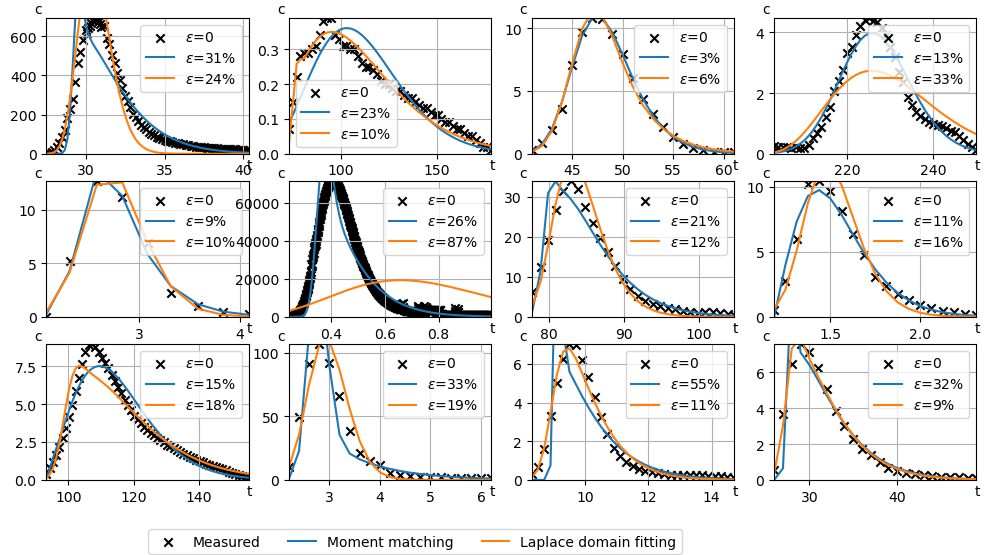

In [15]:
from matplotlib.transforms import offset_copy
# np.random.seed(1)
Nrows = 3
Ncols = 4
fig,axes = plt.subplots(nrows = Nrows, ncols = Ncols, figsize = (12,6))
np.random.seed(42)
rand_i_btcs = np.sort(np.random.choice(list(range(n_btcs)),size = Nrows*Ncols, replace = False))
j=0
for i_btc in rand_i_btcs:
    t,btc,x,est_btc_lap = ts_m_0[i_btc],btcs_m_0[i_btc],xs_m[i_btc],btcs_rec_laplace[i_btc]
    axes[j//Ncols][j%Ncols].scatter(t,btc, c='k', marker = 'x',label = '$\epsilon$=0')
    axes[j//Ncols][j%Ncols].set_ylabel('c', rotation=0)
    axes[j//Ncols][j%Ncols].set_xlabel('t', loc='right', labelpad=-10)
    if memory_func == 'first order':
        est_btc_mom = btcs_rec_moments[i_btc]
        axes[j//Ncols][j%Ncols].plot(t, est_btc_mom*np.trapezoid(btc,t)/np.trapezoid(est_btc_mom,t),label = r'$\epsilon$='+format(RMSDs_moments[i_btc],'.0%'), c = colors[0])
    
    axes[j//Ncols][j%Ncols].plot(t, est_btc_lap*np.trapezoid(btc,t)/np.trapezoid(est_btc_lap,t),label = r'$\epsilon$='+format(RMSDs_laplace[i_btc],'.0%'), c = colors[1])
    
    axes[j//Ncols][j%Ncols].set_xlim(t[btc>np.max(btc)*0.001][0],t[btc>np.max(btc)*0.01][-1])
    axes[j//Ncols][j%Ncols].set_ylim(0.0,np.max(btc))
    # axes[j//Ncols][j%Ncols].set_title(names[i_btc], loc='right',pad = -50)
    axes[j//Ncols][j%Ncols].legend()

    axes[j//Ncols][j%Ncols].grid()
    axes[j//Ncols][j%Ncols].yaxis.set_label_coords(-0.04,1.01)
    axes[j//Ncols][j%Ncols].xaxis.set_label_coords(1.02,-0.03)

    j+=1
handles, _ = axes[-1][-1].get_legend_handles_labels()
if memory_func == memory_func:
    labels = ['Measured','Moment matching', 'Laplace domain fitting']#, 'KL-DNN-MAP']
else:
    labels = ['Measured', 'Laplace domain fitting', 'KL-DNN-MAP']
fig.legend(handles, labels, loc=(0.15,0.0015), ncols = 3)

In [16]:
best_params_prior = params_laplace.copy()
if memory_func == 'first order':
    best_params_prior[RMSDs_moments<RMSDs_laplace] = params_moments[RMSDs_moments<RMSDs_laplace]

In [17]:
dim_scaling = np.concatenate((vs_peak[:,None],np.ones(n_btcs)[:,None],np.ones(n_btcs)[:,None],np.ones(n_btcs)[:,None]),axis = 1)
dimless_best_params_prior = best_params_prior/dim_scaling

In [18]:
if memory_func == 'first order':
    RMSDs_best_prior = np.minimum(RMSDs_laplace,RMSDs_moments)
    is_outlier = RMSDs_best_prior>0.25
else:
    RMSDs_best_prior = RMSDs_laplace
    is_outlier = RMSDs_best_prior>0.4

print(np.mean(is_outlier))
mean_log_params = np.mean(np.log(dimless_best_params_prior)[~is_outlier], axis=0)
cov_log_params = np.cov(np.log(dimless_best_params_prior)[~is_outlier], rowvar=0)
cov_log_params_sqrt = sp.linalg.sqrtm(cov_log_params)

0.22491349480968859


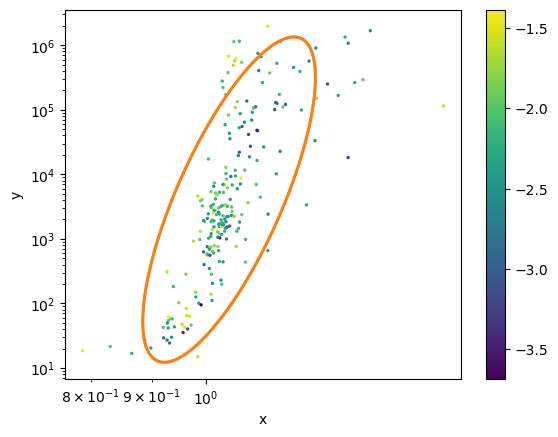

In [19]:
pars_index = [0,1]
# 1️⃣ Eigen-decomposition
eigvals, eigvecs = np.linalg.eigh(4*cov_log_params[pars_index][:,pars_index])

# 2️⃣ Parameterize unit circle
theta = np.linspace(0, 2*np.pi, 200)
circle = np.vstack((np.cos(theta), np.sin(theta)))

# 3️⃣ Scale to ellipse in log-space
ellipse_log = (
    eigvecs @ np.diag(np.sqrt(eigvals)) @ circle
    + mean_log_params[pars_index][:,None]
)

# 4️⃣ Transform back to original space
ellipse = np.exp(ellipse_log)

# 5️⃣ Plot
plt.figure()
plt.loglog(ellipse[0], ellipse[1], 'tab:orange', lw=2)
plt.loglog(ellipse[0], ellipse[1], 'tab:orange', lw=2)
plt.scatter(*dimless_best_params_prior[~is_outlier][:,pars_index].T, c = np.log(np.minimum(RMSDs_laplace,RMSDs_moments)[~is_outlier]), s = 2.0)
plt.colorbar()
plt.xscale('log')
plt.yscale('log')
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [20]:
from scipy.stats import chi2

rivers   = np.array(rivers_full_name_list)                      # check: len(np.unique(rivers)) should be 25
logp     = np.log(dimless_best_params_prior)[:, 1:]   # log(Pe, beta*kf, kr)
ok       = ~is_outlier   # same outlier rule, all BTCs
d        = logp.shape[1]
r99      = chi2.ppf(0.99, d)

def stats(X): return X.mean(0), np.cov(X, rowvar=False)

def kl_gauss(m0, S0, m1, S1):                         # KL(N0 || N1)
    S1i = np.linalg.inv(S1); dm = m1 - m0
    return 0.5*(np.trace(S1i@S0) + dm@S1i@dm - d + np.log(np.linalg.det(S1)/np.linalg.det(S0)))

mu_all, S_all = stats(logp[ok])
sd_all = np.sqrt(np.diag(S_all))

rows = []
for r in np.unique(rivers):
    held = (rivers == r)
    tr   = ok & ~held
    mu, S = stats(logp[tr])
    te   = logp[ok & held]
    cover = np.nan
    if len(te):                                       # held-out river inside the 99% ellipsoid?
        dx = te - mu
        covered = np.sum(np.einsum('ij,jk,ik->i', dx, np.linalg.inv(S), dx) <= r99)
        all_covered_and_not = len(te)
        cover = np.mean(np.einsum('ij,jk,ik->i', dx, np.linalg.inv(S), dx) <= r99)
    rows.append(dict(river=r, n_out=int(np.sum(ok & held)),
                     dmu=(mu-mu_all)/sd_all,                  # mean shift in units of full-data std
                     vratio=np.diag(S)/np.diag(S_all),        # variance ratio
                     kl=kl_gauss(mu_all, S_all, mu, S),       # drift of the whole Gaussian
                     cover=cover,
                    covered = covered,
                    all_covered_and_not = all_covered_and_not))



In [21]:
sum([x['covered'] for x in rows if x['cover']>0.9])/sum([x['all_covered_and_not'] for x in rows if x['cover']>0.9]),sum([x['all_covered_and_not'] for x in rows if x['cover']>0.9])

(np.float64(0.9890710382513661), 183)

In [22]:
[x['cover'] for x in rows if x['river'] == 'Stringer Creek'],[x['cover'] for x in rows if x['river'] == 'Smiley Creek']

([np.float64(0.6666666666666666)], [np.float64(0.35714285714285715)])

In [23]:
np.mean(np.einsum('ij,jk,ik->i', logp[ok]-mu_all, np.linalg.inv(S_all), logp[ok]-mu_all) <= r99)

np.float64(0.96875)

AttributeError: 'numpy.ndarray' object has no attribute 'get_yticklabels'

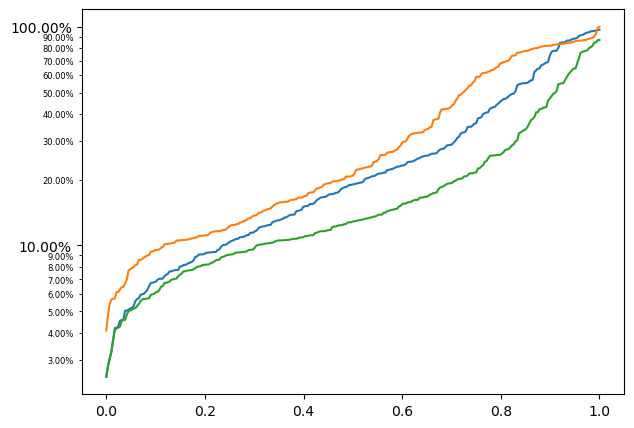

In [24]:
import matplotlib
fig,ax = plt.subplots(figsize = (7,5))

if memory_func == 'first order':
    ax.semilogy(np.linspace(0,1,len(RMSDs_moments)),np.sort(RMSDs_moments),label = 'Moment match.',c = colors[0])
    ax.semilogy(np.linspace(0,1,len(RMSDs_moments)),np.sort(np.minimum(RMSDs_laplace,RMSDs_moments)),label = 'Best fit.',c = colors[2])
ax.semilogy(np.linspace(0,1,len(RMSDs_laplace)),np.sort(RMSDs_laplace),label = 'Laplace dom. fit.',c = colors[1])


ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals = 2,xmax = 1))
ax.yaxis.set_minor_formatter(matplotlib.ticker.PercentFormatter(decimals = 2,xmax = 1))

ax.tick_params(axis='y', which='major', labelsize=10)
ax.tick_params(axis='y', which='minor', labelsize=6)
for label in ax.get_yticklabels():
    label.set_verticalalignment('bottom')

ax.legend(ncols = 2)
ax.set_ylim(0.01,1.0)
ax.set_xlim(0,1)
ax.grid(which='major')
ax.grid(which='minor',linewidth = 0.4)
ax.set_xlabel('Cumulative fraction of fitted breakthrough curves')
ax.set_ylabel('Root-mean-square error', labelpad= 0)

## Global optimization

In [25]:
def RMSE_t_scale(i_btc,t_scale,ts_synth,synth_btc):
    t_peak_synth = ts_synth[np.argmax(synth_btc)]
    btc_interp = np.interp(ts_m_0[i_btc],ts_synth*t_scale/t_peak_synth,synth_btc)
    a_fac = np.trapezoid(btc_interp*btcs_m_0[i_btc],x = ts_m_0[i_btc])/np.trapezoid(btc_interp**2,x = ts_m_0[i_btc])
    btc_interp_scaled = btc_interp*a_fac
    RMSD = np.sqrt(np.trapezoid((btcs_m_0[i_btc]-btc_interp_scaled)**2,x = ts_m_0[i_btc])/np.trapezoid((btcs_m_0[i_btc])**2,x = ts_m_0[i_btc]))
    return RMSD,btc_interp_scaled,a_fac

In [26]:
global_seed = 43

In [27]:
from scipy.optimize import NonlinearConstraint
p_value = 0.99
def constraint_ellipsoid(mu,Sigma):
    Sigma_inv = np.linalg.inv(Sigma)
    chi2_radius = chi2.ppf(p_value, 3)
        
    def ellipsoid_constraint(x):
        dx = x - mu
        return dx @ Sigma_inv @ dx
    
    constraint = NonlinearConstraint(
        ellipsoid_constraint,
        -np.inf,
        chi2_radius
    )
    return constraint

In [28]:
low_bound = mean_log_params-3*np.sqrt(np.diag(cov_log_params))
up_bound = mean_log_params+3*np.sqrt(np.diag(cov_log_params))
bounds_all = [(low_bound[0],up_bound[0])]+[(np.log(15),np.log(5500))]+[(low_bound[i],up_bound[i]) for i in range(2,4)]
if memory_func == 'power law':
    bounds_all[-1] = (0.0,1.0)

## Uncertainty quantification

In [30]:
%%time
np.random.seed(global_seed)
Nt = 150
n_synth = 5000
rand_params_synth = np.exp(np.random.multivariate_normal(mean_log_params[1:], cov_log_params[1:][:,1:]*2, size=n_synth*3))
rand_params_synth = rand_params_synth[(rand_params_synth[:,0]<5500)&(rand_params_synth[:,0]>15)]
rand_params_synth = rand_params_synth[:n_synth]

ts_synth = np.linspace(0,T_,T_*Nt+1)[1:]
synth_btcs = np.array([forward.laplace.ADEMF_1D(ts_synth,[1.0],1.0,theta[0],theta[1]/theta[2],[theta[2],theta[2]],'first order','infinite')[:,-1] for theta in rand_params_synth])
ts_peak_synth = ts_synth[np.argmax(synth_btcs,axis = 1)]
# btcs_synth_peak = np.array([np.interp(ts_synth*peak,ts_synth,btc)*peak for peak,btc in zip(ts_peak_synth,synth_btcs)])

CPU times: total: 4min 23s
Wall time: 4min 27s


In [253]:
%%time
N = 30
btc_mean = np.mean(synth_btcs,axis = 0)
btc_diff = synth_btcs-btc_mean
C = btc_diff.T @ btc_diff / (btc_diff.shape[0] - 1)
eigvals, eigvecs = np.linalg.eigh(C)
idx = np.argsort(eigvals)[::-1]
N_terms = N
lambdas = eigvals[idx][:N_terms]
phis = eigvecs[:, idx][:,:N_terms]
Zs = (btc_diff @ eigvecs[:, idx])[:,:N_terms]

CPU times: total: 39.9 s
Wall time: 8.21 s


In [254]:
np.random.seed(global_seed+1)
lens_btcs = np.array([len(btcs_m[i_btc]) for i_btc in np.arange(n_btcs)])
i_btcs_rand = np.random.choice(np.arange(n_btcs)[(lens_btcs<150)&(lens_btcs>30)],6,replace = False)
np.array(names_list)[i_btcs_rand],[len(btcs_m[i_btc]) for i_btc in i_btcs_rand]

ValueError: Cannot take a larger sample than population when 'replace=False'

In [ ]:
est_params = np.load('best_est_params_first order_infinite.npy')[:,1:].astype(float)

In [ ]:
mass_ratio = np.zeros(n_btcs)
for i_btc in range(n_btcs):
    t_, x = ts_m[i_btc], xs_m[i_btc]
    v, Pe, bkf, kr = est_params[i_btc][-4:]           # adapt to the real layout
    tl  = np.linspace(1e-6, 50*t_[np.argmax(btcs_m[i_btc])], 6000)
    area_model = a_vals[i_btc]*np.trapezoid(
        forward.laplace.ADEMF_1D(tl,[x],v,min(Pe,5000),bkf/kr,[kr,kr],'first order','infinite')[:,-1], tl)
    area_data  = np.trapezoid(btcs_m[i_btc]-background_cs_m[i_btc], t_)
    mass_ratio[i_btc] = area_model/area_data
print(np.percentile(mass_ratio, [10, 25, 50, 75, 90]))

In [ ]:
est_params = np.concatenate((mass_ratio[:,None],est_params),axis = 1)

In [ ]:
# =====================================================================
# CELL 1 -- surrogate posterior + differential-evolution MCMC
# Needs from the notebook: ts_synth, synth_btcs, rand_params_synth, ts_peak_synth,
#   btc_mean, phis, Zs (the 5000-sample / N=30 KL set built in the "UQ" section),
#   mean_log_params, cov_log_params, est_params_linear, i_btcs_rand,
#   ts_m, btcs_m, ts_m_0, btcs_m_0, xs_m, ts_peak, forward, utils
# =====================================================================
import numpy as np
from scipy.spatial import Delaunay
from scipy.linalg import cho_factor, cho_solve, LinAlgError
from scipy.stats import invgamma, halfnorm, multivariate_normal

# ---------------- settings ----------------
N_POP, N_BURN, N_ITER = 50, 500, 2500      # chains, burn-in, total iterations
PE_BOUNDS      = (15.0, 5000.0)
LM_BOUNDS      = (np.log(0.8), np.log(1.2))  # log of relative amplitude m_rel (log-uniform)
L_SHAPE        = 3.0                         # inverse-gamma shape of the GP length scale (prior AND init)
SIGMA_XI_SCALE = 0.05                        # half-normal scale of relative model discrepancy (check vs your NRMSE!)
SIGMA_EPS_FAC  = 0.005                       # half-normal scale of noise, times max(c*)
FLOOR_FAC      = 0.005                       # fixed noise floor, times max(c*)
K_FOLD         = 10                          # folds for the surrogate-error map
MU_Y, COV_Y    = mean_log_params[1:], cov_log_params[1:][:, 1:]
COV_Y_INV      = np.linalg.inv(COV_Y)
D              = 8                           # [ln m_rel, t_s, ln Pe, ln b*kf, ln kr, ln l, ln sigma_xi, ln sigma_eps]
# ---------------- surrogate (vectorised barycentric interpolation) ----------------
def interp_batch(tri, vals, X):
    """Barycentric interpolation of vals (n_pts, k) at X (n, 3). Returns (n, k), inside-hull flag (n,)."""
    X = np.atleast_2d(X)
    s = tri.find_simplex(X)
    inside = s >= 0
    s0 = np.where(inside, s, 0)
    T, r = tri.transform[s0, :3], tri.transform[s0, 3]
    b = np.einsum('nij,nj->ni', T, X - r)
    w = np.concatenate([b, 1.0 - b.sum(1, keepdims=True)], axis=1)
    return np.einsum('ni,nik->nk', w, vals[tri.simplices[s0]]), inside


logY = np.log(rand_params_synth)
tri  = Delaunay(logY)
ZT   = np.concatenate([Zs, ts_peak_synth[:, None]], axis=1)      # interpolate Z and peak time together


def kfold_error_map(seed=0):
    """Surrogate NRMSE at every synthetic sample, predicted from the other folds (conservative LOO).
    Peak time of the interpolant is aligned to the true one, as in the DROSTE leave-one-out test."""
    n = len(logY)
    folds = np.random.default_rng(seed).permutation(n) % K_FOLD
    err = np.full(n, np.nan)
    for k in range(K_FOLD):
        te, trn = folds == k, folds != k
        tri_k = Delaunay(logY[trn])
        P, ins = interp_batch(tri_k, ZT[trn], logY[te])
        for i, p, ok in zip(np.where(te)[0], P, ins):
            if not ok:
                continue                                   # outside the hull of the other folds
            rec = btc_mean + p[:-1] @ phis.T
            pred = np.interp(ts_synth, ts_synth * p[-1] / ts_peak_synth[i], rec)
            err[i] = utils.errors.RMSD_func(ts_synth, synth_btcs[i], pred)
    err[np.isnan(err)] = np.nanmax(err)                    # boundary samples: be conservative
    return err


err_map = kfold_error_map()[:, None]


def t_scale_range(i_btc, rel=0.8):
    t, c = ts_m_0[i_btc], btcs_m_0[i_btc]
    cn = c / np.max(c)
    i0, i1 = np.where(cn > rel)[0][[0, -1]]
    cross = lambda i: t[i-1] + (t[i] - t[i-1]) / (cn[i] - cn[i-1]) * (rel - cn[i-1])
    return [cross(i0), cross(i1 + 1)]


# ---------------- posterior of one BTC ----------------
class BTCPosterior:
    def __init__(self, t, c, x, t_range, est, t_peak):
        """est = (amplitude, v, Pe, b*kf, kr) of the DROSTE estimate; t_peak = measured peak time."""
        self.t, self.c, self.x, self.t_range, self.est = np.asarray(t, float), np.asarray(c, float), x, t_range, est
        a, v, Pe, bkf, kr = est
        dl = forward.laplace.ADEMF_1D(ts_synth, [1.0], 1.0, Pe, bkf / kr, [kr, kr], 'first order', 'infinite')[:, -1]
        m0 = np.interp(self.t, ts_synth * x / v, dl) * a
        # FIXED likelihood support (does not depend on the sampled parameters)
        self.mask = (m0 > 1e-3 * m0.max()) | (self.c > 1e-3 * self.c.max())
        self.tm, self.cm = self.t[self.mask], self.c[self.mask]
        self.D2 = (self.tm[:, None] - self.tm[None, :]) ** 2
        self.l_scale = 0.5 * t_peak
        self.se_scale = SIGMA_EPS_FAC * self.c.max()
        self.floor = FLOOR_FAC * self.c.max()
        self.ts0 = x * ts_synth[np.argmax(dl)] / v           # DROSTE time scale
        self.sd = np.array([(LM_BOUNDS[1] - LM_BOUNDS[0]) / np.sqrt(12), (t_range[1] - t_range[0]) / np.sqrt(12),
                            *np.sqrt(np.diag(COV_Y)), 1.0, 1.0, 1.0])   # prior scales (for proposal noise)

    # surrogate prediction at measured times (and optionally at a finer grid)
    def curve(self, z, tp, ts, lm, tgrid=None):
        rec = btc_mean + z @ phis.T
        raw = np.interp(self.t * tp / ts, ts_synth, rec)     # = interp of the stretched basis; linear, so same result
        a = np.trapezoid(raw * self.c, self.t) / np.trapezoid(raw ** 2, self.t) * np.exp(lm)
        out = a * raw
        return out if tgrid is None else (out, a * np.interp(tgrid * tp / ts, ts_synth, rec))

    def loglik(self, z, tp, ts, lm, ell, sx, se, e_int):
        model_all = self.curve(z, tp, ts, lm)
        if not np.all(np.isfinite(model_all)):
            return -np.inf
        model, r = model_all[self.mask], self.cm - model_all[self.mask]
        S = model[:, None] * (sx ** 2 * np.exp(-self.D2 / ell ** 2)) * model[None, :]       # multiplicative GP
        S[np.diag_indices_from(S)] += se ** 2 + self.floor ** 2 + (e_int * np.sqrt(np.mean(model ** 2))) ** 2
        try:
            cf = cho_factor(S, lower=True)
        except LinAlgError:
            return -np.inf
        return -0.5 * r @ cho_solve(cf, r) - np.log(np.diag(cf[0])).sum() - 0.5 * len(r) * np.log(2 * np.pi)

    def log_post_pop(self, TH):
        """TH: (n, 8). Returns log-posterior (n,), -inf outside the support / the sampled region."""
        TH = np.atleast_2d(TH)
        lm, ts, ly = TH[:, 0], TH[:, 1], TH[:, 2:5]
        ell, sx, se = np.exp(TH[:, 5]), np.exp(TH[:, 6]), np.exp(TH[:, 7])
        ok = ((lm >= LM_BOUNDS[0]) & (lm <= LM_BOUNDS[1]) & (ts >= self.t_range[0]) & (ts <= self.t_range[1])
              & (ly[:, 0] >= np.log(PE_BOUNDS[0])) & (ly[:, 0] <= np.log(PE_BOUNDS[1])))
        P, ins = interp_batch(tri, ZT, ly)
        E, _ = interp_batch(tri, err_map, ly)
        ok &= ins                                            # never leave the region covered by the synthetic samples
        dy = ly - MU_Y
        prior = (-0.5 * np.einsum('ni,ij,nj->n', dy, COV_Y_INV, dy)
                 + invgamma.logpdf(ell, L_SHAPE, scale=self.l_scale) + TH[:, 5]           # + ln-Jacobian
                 + halfnorm.logpdf(sx, scale=SIGMA_XI_SCALE) + TH[:, 6]
                 + halfnorm.logpdf(se, scale=self.se_scale) + TH[:, 7])
        out = np.full(len(TH), -np.inf)
        for k in np.where(ok)[0]:
            out[k] = prior[k] + self.loglik(P[k, :-1], P[k, -1], ts[k], lm[k], ell[k], sx[k], se[k], E[k, 0])
        out[~np.isfinite(out)] = -np.inf
        return out

    def init_population(self, n, rng):
        keep = []
        for _ in range(50):
            m = 4 * n
            C = np.empty((m, D))
            C[:, 0] = rng.normal(0, 0.1, m)
            C[:, 1] = self.ts0 * (1 + 0.02 * rng.standard_normal(m))
            C[:, 2:5] = rng.multivariate_normal(np.log(self.est[2:]), COV_Y / 16
# ---------------- sampler: differential-evolution MCMC, two-block updates ----------------
def run_demc(post, rng, n_pop=N_POP, n_burn=N_BURN, n_iter=N_ITER, eps_rel=np.sqrt(3e-4)):
    """DREAM-style differential-evolution MCMC: random crossover (each proposal moves a random subset of the
    8 unknowns), gamma = 2.38/sqrt(2*d_sel), mode jumps (gamma=1, all dims) every 10th iteration, two-block updates,
    burn-in step-size adaptation and stuck-chain replacement (burn-in only)."""
    X = post.init_population(n_pop, rng)
    lp = post.log_post_pop(X)
    chain, logp, acc = np.empty((n_iter + 1, n_pop, D)), np.empty((n_iter + 1, n_pop)), np.zeros((n_iter, n_pop), bool)
    chain[0], logp[0] = X, lp
    gscale, h, CRs = 1.0est_params[i_btc], ts_peak[i_btc])
    run = run_demc(pm, rng)
    post_models.append(pm); post_runs.append(run)
    post = run['chain'][run['n_burn']:]
    print(f"[{kk}] {names_list[i_btc]}: acceptance {run['acc'][run['n_burn']:].mean():.2f}, "
          f"max split-Rhat {split_rhat(post).max():.3f}, gamma scale {run['gamma']:.2f}, resets {run['n_reset']}")
    print('     Rhat   :', dict(zip(names_par, np.round(split_rhat(post), 3))))
    print('     post/prior var of ln(Pe, b*kf, kr):',
          np.round(post[..., 2:5].reshape(-1, 3).var(0, ddof=1) / np.diag(COV_Y), 3),
          '| median s_xi, s_eps/max(c):',
          np.round(np.exp(np.median(post[..., 6])), 4), np.round(np.exp(np.median(post[..., 7])) / pm.c.max(), 4))
, n_pop // 2, np.array([1 / 3, 2 / 3, 1.0])
    blocks = [(np.arange(h), np.arange(h, n_pop)), (np.arange(h, n_pop), np.arange(h))]
    n_reset = 0
    for it in range(n_iter):
        jump = (it % 10 == 0)
        for idx, pool in blocks:
            nb_ = len(idx)
            rs = np.array([rng.choice(pool, 2, replace=False) for _ in range(nb_)])
            sel = rng.random((nb_, D)) < rng.choice(CRs, nb_)[:, None]
            sel[np.arange(nb_), rng.integers(0, D, nb_)] = True       # at least one dimension moves
            if jump:
                sel[:] = True
            g = np.ones(nb_) if jump else gscale * 2.38 / np.sqrt(2 * sel.sum(1))
            step = g[:, None] * (X[rs[:, 0]] - X[rs[:, 1]]) + eps_rel * post.sd * rng.standard_normal((nb_, D))
            prop = X[idx] + sel * step
            lpp = post.log_post_pop(prop)
            a = np.log(rng.random(nb_)) < (lpp - lp[idx])
            X[idx[a]], lp[idx[a]] = prop[a], lpp[a]
            acc[it, idx] = a
        if it < n_burn and it % 50 == 49:                      # step-size adaptation (burn-in only)
            rate = acc[it - 49:it + 1][np.arange(it - 49, it + 1) % 10 != 0].mean()
            gscale *= 0.7 if rate < 0.15 else (1.3 if rate > 0.35 else 1.0)
        if it < n_burn and it % 100 == 99:                     # stuck chains -> restart on a random good chain
            m = logp[max(0, it - 98):it + 1].mean(0)
            q1, q3 = np.percentile(m, [25, 75])
            bad = np.where(m < q1 - 2 * (q3 - q1))[0]
            good = np.where(m >= q3)[0]
            for b in bad:
                k = rng.choice(good); X[b], lp[b] = X[k], lp[k]
            n_reset += len(bad)
        chain[it + 1], logp[it + 1] = X, lp
    return dict(chain=chain, logp=logp, acc=acc, n_burn=n_burn, gamma=gscale, n_reset=n_reset)


def split_rhat(x):
    """Split-Rhat. x: (n_iter, n_chains, D)."""
    n = x.shape[0] // 2
    y = np.concatenate([x[:n], x[n:2 * n]], axis=1)
    W, B = y.var(0, ddof=1).mean(0), n * y.mean(0).var(0, ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W)


# ---------------- run ----------------
rng = np.random.default_rng(42)
post_models, post_runs = [], []
names_par = ['ln m_rel', 't_s', 'ln Pe', 'ln b*kf', 'ln kr', 'ln l', 'ln s_xi', 'ln s_eps']
for kk, i_btc in enumerate(i_btcs_rand):
    pm = BTCPosterior(ts_m[i_btc], btcs_m[i_btc], xs_m[i_btc], t_scale_range(i_btc),
                      , m)
            C[:, 5] = np.log(invgamma.rvs(L_SHAPE, scale=self.l_scale, size=m, random_state=rng))
            C[:, 6] = np.log(halfnorm.rvs(scale=SIGMA_XI_SCALE, size=m, random_state=rng))
            C[:, 7] = np.log(halfnorm.rvs(scale=self.se_scale, size=m, random_state=rng))
            keep += list(C[np.isfinite(self.log_post_pop(C))])
            if len(keep) >= n:
                return np.array(keep[:n])
        raise RuntimeError('could not initialise a finite-posterior population')





In [ ]:
# =====================================================================
# CELL 2 -- posterior predictive plots (pooled post-burn-in samples, surrogate only: no forward solves)
# =====================================================================
from matplotlib.lines import Line2D

N_DRAW = 300
rng = np.random.default_rng(1)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 7.0), constrained_layout=True)
axes = axes.flatten()
for kk, i_btc in enumerate(i_btcs_rand):
    pm, run = post_models[kk], post_runs[kk]
    nb = run['n_burn']
    S, LP = run['chain'][nb:].reshape(-1, D), run['logp'][nb:].reshape(-1)
    imap = np.argmax(LP)                                      # MAP from the stored log-posterior values
    sel = rng.choice(len(S), N_DRAW, replace=False)
    t_plot = np.linspace(pm.t[0], pm.t[-1], 300)

    def predict(th):
        P, _ = interp_batch(tri, ZT, th[None, 2:5])
        z, tp = P[0, :-1], P[0, -1]
        y_meas, y_plot = pm.curve(z, tp, th[1], th[0], t_plot)
        return y_meas, y_plot, pm.x / th[1] * tp                  # last: velocity v = L * t_peak(y) / t_s

    pred = [predict(S[j]) for j in sel]
    Ymeas, Yplot, Vs = (np.array([p[i] for p in pred]) for i in range(3))
    eps_draw = np.array([utils.errors.RMSD_func(pm.t, pm.c, y) for y in Ymeas])
    # predictive band: parameter uncertainty + discrepancy + noise (marginal, diagonal approximation)
    sd_pred = np.sqrt((Yplot * np.exp(S[sel, 6])[:, None]) ** 2 + (np.exp(S[sel, 7]) ** 2 + pm.floor ** 2)[:, None])
    Ypred = Yplot + sd_pred * rng.standard_normal(Yplot.shape)

    axes[kk].fill_between(t_plot, *np.percentile(Ypred, [20, 80], axis=0), color='r', alpha=0.10)
    axes[kk].fill_between(t_plot, *np.percentile(Yplot, [20, 80], axis=0), color='r', alpha=0.25)
    y_map_m, y_map_p, v_map = predict(S[imap])
    eps_map = utils.errors.RMSD_func(pm.t, pm.c, y_map_m)
    axes[kk].plot(t_plot, y_map_p, c='r')

    a, v_d, Pe_d, bkf_d, kr_d = pm.est                         # DROSTE estimate
    dl = forward.laplace.ADEMF_1D(ts_synth, [1.0], 1.0, Pe_d, bkf_d / kr_d, [kr_d, kr_d], 'first order', 'infinite')[:, -1]
    
    eps_d,a = utils.errors.RMSD_func(pm.t, pm.c, np.interp(pm.t, ts_synth * pm.x / v_d, dl),return_a = True)

    axes[kk].plot(t_plot, np.interp(t_plot, ts_synth * pm.x / v_d, dl) * a, c='tab:blue')

    axes[kk].plot(pm.t, pm.c, c='k', marker='o', markersize=2.0, linewidth=1.0, linestyle='dotted')
    axes[kk].set_xlim(pm.t[pm.t>0][0], pm.t[-3]); axes[kk].grid()
    axes[kk].set_ylabel(r'$c$ [ppb]', rotation=0)
    axes[kk].set_xlabel(r'$t$ [h]')

    axes[kk].yaxis.set_label_coords(-0.04,1.01)
    axes[kk].xaxis.set_label_coords(0.95,-0.1)
    
    axes[kk].set_title(names_list[i_btc], loc='center')
    


    axes[kk].fill_between(
        [0.6, 0.7],
        [0.92,0.92],
        [0.98, 0.98],
        transform=axes[kk].transAxes,
        color = 'r',alpha = 0.2,zorder = 12)

    
    axes[kk].plot(
        [0.83,0.88],
        [0.95,0.95],
        transform=axes[kk].transAxes,
        c = 'r',zorder = 12
    )

    axes[kk].plot(
        [0.93,0.98],
        [0.95,0.95],
        transform=axes[kk].transAxes,
        c = 'tab:blue',zorder = 12
    )
    
    pct = lambda x, f: '(' + ','.join(format(q, f) for q in np.percentile(x, [20, 50, 80])) + ')'
    Y = np.exp(S[sel, 2:5])
    rows = [[r'$\varepsilon$', pct(eps_draw, '.1%'), format(eps_map, '.1%'), format(eps_d, '.1%')],
            [r'$m_\mathrm{rel}$', pct(np.exp(S[sel, 0]), '.2f'), format(np.exp(S[imap, 0]), '.2f'), '1.00'],
            [r'$v$', pct(Vs, '.3f'), format(v_map, '.3f'), format(v_d, '.3f')]]
    for j, (nm, f, dv) in enumerate(zip([r'$Pe$', r'$\beta\hat{k}_f$', r'$\hat{k}_r$'], ['.0f', '.2f', '.1f'], [Pe_d, bkf_d, kr_d])):
        rows.append([nm, pct(Y[:, j], f), format(np.exp(S[imap, 2 + j]), f), format(dv, f)])
    table = axes[kk].table(cellText=[['', '', '', '']] + rows, loc='top', bbox=[1 - 0.59, 1 - 0.68, 0.59, 0.68])
    table.set_zorder(10)
    for cell in table.get_celld().values():
        cell.set_facecolor('white'); cell.set_alpha(0.7); cell.get_text().set_ha('left')
        cell.set_zorder(10); cell.PAD = 0.03; cell.get_text().set_zorder(11); cell.set_edgecolor('gray')
    table.auto_set_column_width(col=list(range(4)))

handles = [Line2D([0], [0], c='k', marker='o', markersize=2.0, linewidth=1.0, linestyle='dotted'),
           plt.Rectangle((0, 0), 1, 1, color='r', alpha=0.25), plt.Rectangle((0, 0), 1, 1, color='r', alpha=0.10),
           Line2D([0], [0], c='r'), Line2D([0], [0], c='tab:blue')]
labels = ['Measured', 'Parameter uncertainty (20-80%)', 'Predictive incl. discrepancy and noise (20-80%)',
          'MAP estimate', 'DROSTE estimate']
fig.legend(handles, labels, loc='lower center', ncols=5, bbox_to_anchor=(0.5, -0.05))